# Mask Detection

### imports

In [ ]:
import cv2

from cv_utils import ImageLoader, display, display_grid, ImageProcessor
from cv_utils.detection import TemplateDetector, TemplateMatchingPipeline
from cv_utils.detection.template_utils import compare_methods

### Basic Mask Finding

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv

load_dotenv()
PROJECT_ROOT = Path(os.getenv("PROJECT_ROOT"))
DATA_DIR = Path(os.getenv("DATA_DIR"))

In [15]:
org_img_path = DATA_DIR / "logo_g.jpeg"
image = ImageLoader.load(org_img_path, "rgb")

mask_img_path = DATA_DIR / "logo_g_mask.jpeg"
mask = ImageLoader.load(mask_img_path, "rgb")

OpenCV version: 4.8.0


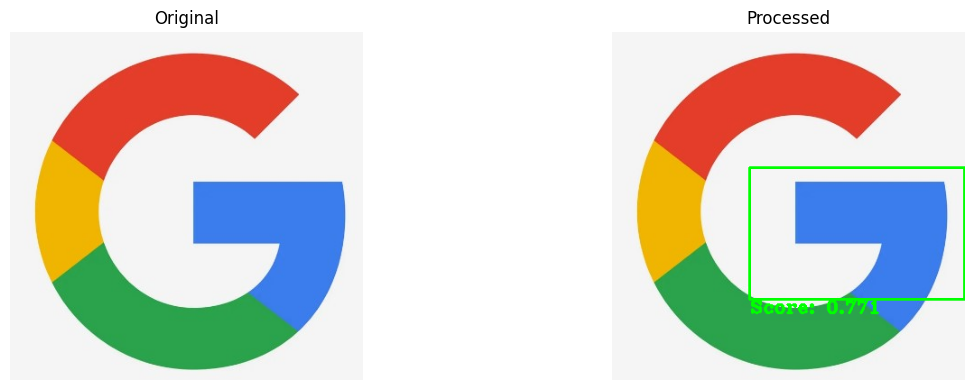

--- PIPELINE METADATA --- 
Match Found: True
Score: 0.7711987495422363
Location: ((152, 150), (390, 296))


In [16]:
# Task 1: Using new TemplateMatchingPipeline
print(f"OpenCV version: {cv2.__version__}")

# Create pipeline (detector + visualization)
pipeline = TemplateMatchingPipeline(
    template=mask_img_path,
    method="cv2.TM_CCOEFF_NORMED",
    threshold=0.7,
    show_score=True,
    drawing_params={'color': (0, 255, 0), 'thickness': 3}
)

# Process image
processor = ImageProcessor(img_src=org_img_path, pipeline=pipeline)
result = processor.process()

# Show metadata
processor.print_metadata()

### Multi-Method Mask Finding

In [17]:
# Use defaults from TemplateMatcher
# compare_methods() will automatically use:
# - TemplateMatcher.SUPPORTED_METHODS for all methods
# - TemplateMatcher.DEFAULT_THRESHOLDS for thresholds

from cv_utils.detection.matchers import TemplateMatcher

print("Available methods:")
for method in TemplateMatcher.SUPPORTED_METHODS:
    thresh = TemplateMatcher.DEFAULT_THRESHOLDS.get(method, "N/A")
    print(f"  {method:20s} | threshold: {thresh}")

Available methods:
  cv2.TM_CCOEFF        | threshold: 10000000
  cv2.TM_CCOEFF_NORMED | threshold: 0.7
  cv2.TM_CCORR         | threshold: 50000000
  cv2.TM_CCORR_NORMED  | threshold: 0.8
  cv2.TM_SQDIFF        | threshold: 5000000
  cv2.TM_SQDIFF_NORMED | threshold: 0.3


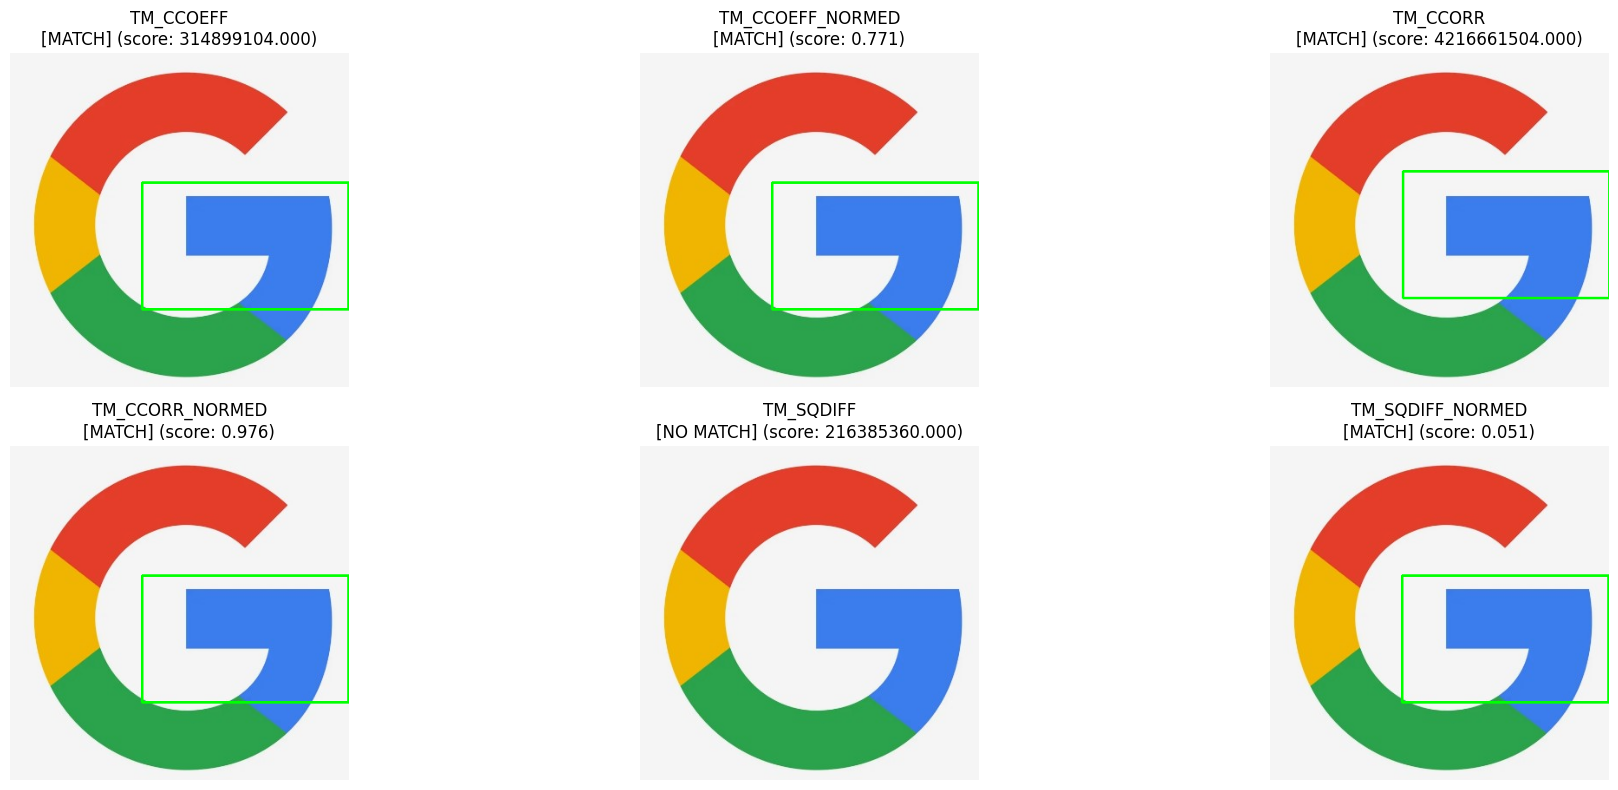

In [18]:
# Task 2: Compare all template matching methods (using defaults)
results, titles, metadata_list = compare_methods(
    image_path=org_img_path,
    template_path=mask_img_path,
    show_score=False
)

# Display all results
display_grid(results, titles=titles, max_cols=3)

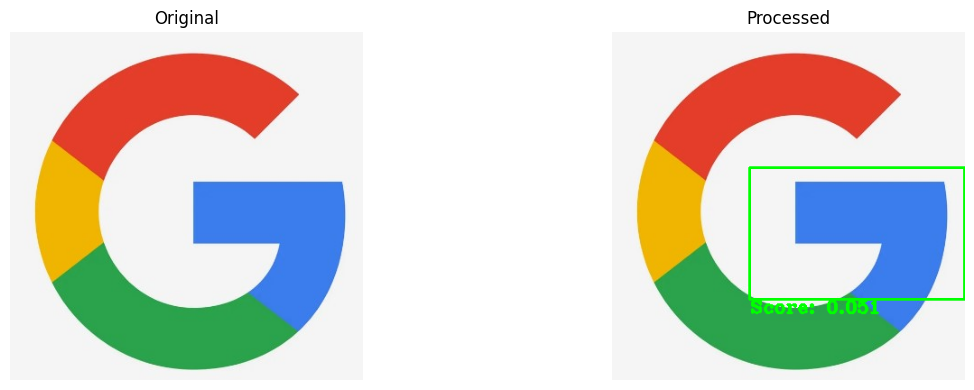

--- PIPELINE METADATA --- 
Match Found: True
Score: 0.05056377127766609
Location: ((152, 150), (390, 296))


In [8]:
# Test SQDIFF_NORMED with custom threshold
pipeline = TemplateMatchingPipeline(
    template=mask_img_path,
    method="cv2.TM_SQDIFF_NORMED",
    threshold=0.15,  # Lower is better for SQDIFF
    show_score=True,
)

processor = ImageProcessor(img_src=org_img_path, pipeline=pipeline)
result = processor.process()
processor.print_metadata()

## Finding Mask in Video

Create a function `find_image_by_mask_in_video(original_video_path, mask_image_path)` that does the following:
- a. Upgrade the search to work with video data. Search for the mask in all frames and draw a rectangle around matches.
- b. Save only the frames that contain matching images (not all frames).
- c. Write "Found in frame #[frame_number]" on the frame image and in the notebook with the actual frame number.
- d. Test this function with the attached black car image and video.
- e. Then demonstrate with any example you like for finding an image in a video.

True
True


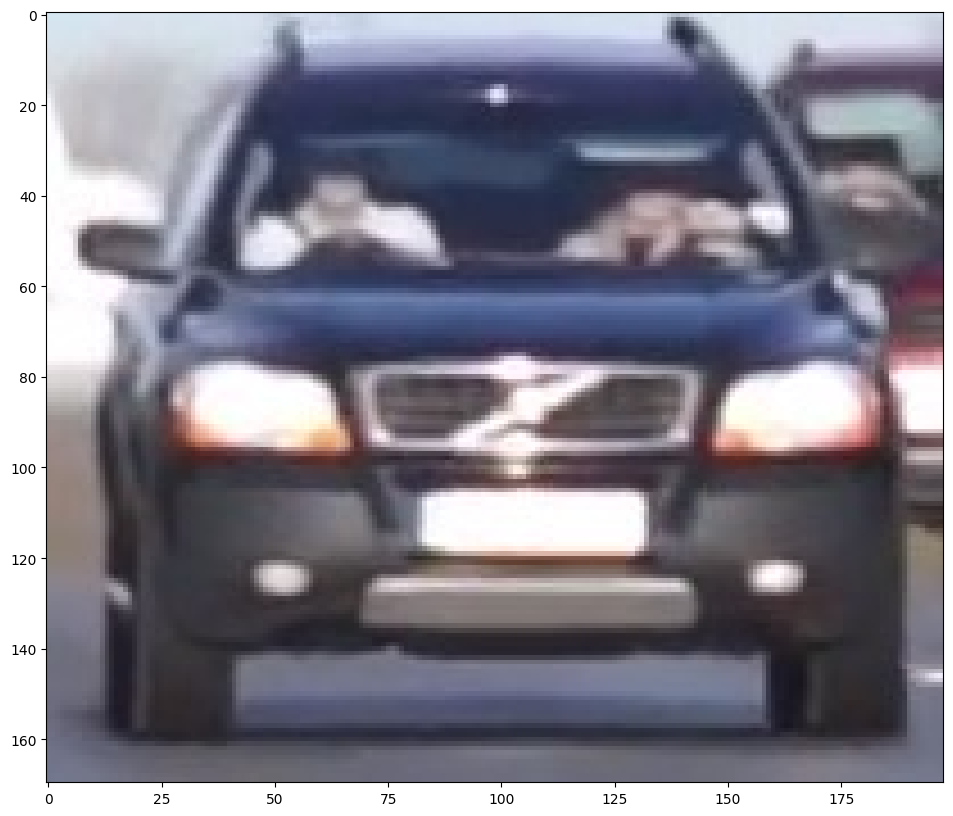

In [9]:
# For video, we'll use VideoProcessor with the pipeline
from cv_utils.video import VideoProcessor

video_path = DATA_DIR / "assignments" / "cars_on_highway (1080p).mp4"
car_mask_path = DATA_DIR / "assignments" / "Car_mask.jpg"

print(video_path.exists())
print(car_mask_path.exists())

display(ImageLoader.load(car_mask_path, "rgb"))

In [10]:
print("Available methods:")
for method in TemplateMatcher.SUPPORTED_METHODS:
    thresh = TemplateMatcher.DEFAULT_THRESHOLDS.get(method, "N/A")
    print(f"  {method:20s} | threshold: {thresh}")

Available methods:
  cv2.TM_CCOEFF        | threshold: 10000000
  cv2.TM_CCOEFF_NORMED | threshold: 0.7
  cv2.TM_CCORR         | threshold: 50000000
  cv2.TM_CCORR_NORMED  | threshold: 0.8
  cv2.TM_SQDIFF        | threshold: 5000000
  cv2.TM_SQDIFF_NORMED | threshold: 0.3


In [11]:
SCALE = 0.5

# Setup for video processing
method = "cv2.TM_SQDIFF_NORMED"
threshold = 0.15

pipeline=TemplateMatchingPipeline(
        template=car_mask_path,
        method=method,
        threshold=threshold,
        scale=SCALE,
        show_score=True,
        drawing_params={'color': (0, 255, 0), 'thickness': 3}
)

video_processor = VideoProcessor(
    pipeline=pipeline,
    video_source=video_path,
    scale=SCALE,
    skip_frames=2,
    # output_title="car_mask",
    display_window="Car Detection",
    show_time=True,
    show_frame_nr=True,
 )

In [12]:
# Process video (press ESC to stop)
video_processor.process(show_display=True)

# Check metadata from last frame
print("\nLast frame metadata:")
print(f"Match found: {pipeline.metadata['match_found']}")
print(f"Score: {pipeline.metadata['score']}")

qt.qpa.plugin: Could not find the Qt platform plugin "wayland" in "/home/dyretna/Dokument/Code/GitHub/opencv-demos-py/.venv/lib/python3.10/site-packages/cv2/qt/plugins"


Match found in frame #474, score: 0.147
Match found in frame #476, score: 0.142
Match found in frame #478, score: 0.134
Match found in frame #480, score: 0.129
Match found in frame #482, score: 0.123
Match found in frame #484, score: 0.116
Match found in frame #486, score: 0.105
Match found in frame #488, score: 0.101
Match found in frame #490, score: 0.080
Match found in frame #492, score: 0.079
Match found in frame #494, score: 0.059
Match found in frame #496, score: 0.047
Match found in frame #498, score: 0.044
Match found in frame #500, score: 0.028
Match found in frame #502, score: 0.026
Match found in frame #504, score: 0.036
Match found in frame #506, score: 0.044
Match found in frame #508, score: 0.062
Match found in frame #510, score: 0.081
Match found in frame #512, score: 0.093
Match found in frame #514, score: 0.107
Match found in frame #516, score: 0.114
Match found in frame #518, score: 0.120
Match found in frame #520, score: 0.127
Match found in frame #522, score: 0.136


In [24]:
print(video_processor)

VIDEO PROCESSOR

--- System ---
OS: Linux | Python: 3.10.8 | OpenCV: 4.12.0

--- Video Settings ---
Source: /home/dyretna/Dokument/Code/GitHub/TH06-applied-ai/data/assignments/cars_on_highway (1080p).mp4
Format: 960x540@50fps | Backend: FFMPEG
Scale: 0.5x | Skip: every 2 frame(s)

--- Pipeline ---
--- Template Matching ---
Template: Car_mask.jpg
Size: 99x85 (scaled 0.5x)
Method: TM_SQDIFF_NORMED
Threshold: 0.15

--- Detection Status ---
Last result: No match
Match score: 0.211

--- Visualization ---
Show score on image: Yes
Box color: Green (0, 255, 0)
Box thickness: 3

